<a href="https://colab.research.google.com/github/iwantogohome/aidata/blob/main/9%EC%A3%BC%EC%B0%A8_%EA%B3%BC%EC%A0%9C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np                                    # 수치 계산을 위한 넘파이 패키지
import pandas as pd                                   # 데이터프레임(표 형식 데이터) 처리를 위한 판다스 패키지
from sklearn.datasets import load_iris                # 사이킷런 내장 데이터셋 중 아이리스(iris) 불러오기 함수

iris = load_iris()                                    # 아이리스 데이터셋 로드
# iris.data         → 꽃의 측정값(꽃받침/꽃잎 길이·너비), shape=(150, 4)
# iris.target       → 품종 레이블(0=setosa, 1=versicolor, 2=virginica)
# iris.feature_names→ ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

df = pd.DataFrame(iris.data, columns=iris.feature_names)  # 4개 특성값을 데이터프레임으로 변환
df['target'] = iris.target                                 # 'target' 열 추가 (꽃 품종 정답 라벨)
# target 값: 0=setosa(붓꽃), 1=versicolor(버시컬러), 2=virginica(버지니카)

df.head()                                             # 데이터프레임 앞 5행 출력 (데이터 모양과 레이블 확인용)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [ ]:
# (중요) 종속변수 y: setosa면 1, 아니면 0으로 변환 (이진 분류용 레이블 생성)
# df['target'] 값이 0이면 True → 1, 그 외(1,2)는 False → 0
y = (df['target'] == 0).astype(int)

# 독립변수 X: 분류가 잘 되는 두 특성만 선택
# 여기서는 꽃잎 길이(petal length)와 꽃잎 너비(petal width)만 사용 → 2차원 데이터
X = df[['petal length (cm)', 'petal width (cm)']].values

# 데이터 크기 확인 (X는 [샘플 수, 특성 수], y는 [샘플 수])
X.shape, y.shape

((150, 2), (150,))

In [ ]:
from sklearn.model_selection import train_test_split   # 학습용/테스트용 데이터 분할 함수 불러오기

# 데이터를 학습(train)과 테스트(test) 세트로 나눔
X_train, X_test, y_train, y_test = train_test_split(
    X,      # 독립변수 (꽃잎 길이, 꽃잎 너비)
    y,      # 종속변수 (Setosa=1, Others=0)
    test_size=0.3,     # 전체 데이터 중 30%는 테스트용, 70%는 학습용
    stratify=y,        # y 비율(1과 0 비율)을 train/test에 동일하게 유지
    random_state=42    # 무작위 분할 시드를 고정 → 실행할 때마다 동일한 결과 보장
)

In [ ]:
from sklearn.preprocessing import StandardScaler   # 표준화 도구 불러오기 (평균=0, 표준편차=1로 변환)

scaler = StandardScaler()   # 표준화 객체 생성

# 학습용 데이터(X_train)의 평균과 표준편차를 기준으로 표준화 수행
X_train_std = scaler.fit_transform(X_train)

# 테스트 데이터(X_test)는 학습 데이터에서 구한 평균·표준편차로만 변환
# (fit을 다시 하면 '데이터 누수' 발생 → 반드시 fit은 train만, test는 transform만 사용합니다.
X_test_std  = scaler.transform(X_test)

In [ ]:
from sklearn.linear_model import LogisticRegression   # 로지스틱 회귀 분류 모델 불러오기

# 로지스틱 회귀 모델 객체 생성
# random_state=42 → 학습 과정에서의 난수 고정 (실행할 때마다 동일한 결과 보장)
clf = LogisticRegression(random_state=42)

# 학습 단계
# 독립변수(X_train_std)와 종속변수(y_train)를 이용해 모델을 훈련
# 즉, 특성과 라벨의 규칙을 학습하는 과정
clf.fit(X_train_std, y_train)

LogisticRegression(random_state=42)

In [ ]:
# 학습된 로지스틱 회귀 모델(clf)을 사용하여 테스트 데이터(X_test_std)에 대한 예측 수행
# 결과는 클래스 레이블(0 또는 1)로 출력됨
y_pred = clf.predict(X_test_std)

# 예측 확률 구하기
# predict_proba() → 각 클래스(0, 1)에 속할 확률 반환 → shape = (샘플 수, 클래스 수)
# [:, 1] → 양성 클래스(1: Setosa)일 확률만 추출
# ROC-AUC 계산 시 '양성 클래스 확률'이 필요하므로 사용
y_proba = clf.predict_proba(X_test_std)[:, 1]

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report

cm = confusion_matrix(y_test, y_pred)
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, pos_label=1)
rec = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)
auc = roc_auc_score(y_test, y_proba)

print("혼동행렬:\n", cm)
print(f"정확도: {acc:.3f}, 정밀도: {prec:.3f}, 재현율: {rec:.3f}, F1: {f1:.3f}, ROC_AUC: {auc:.3f}")
print("\n[분류 리포트]\n", classification_report(y_test, y_pred, target_names=['Others(0)','Setosa(1)']))

혼동행렬:
 [[30  0]
 [ 0 15]]
정확도: 1.000, 정밀도: 1.000, 재현율: 1.000, F1: 1.000, ROC_AUC: 1.000

[분류 리포트]
               precision    recall  f1-score   support

   Others(0)       1.00      1.00      1.00        30
   Setosa(1)       1.00      1.00      1.00        15

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



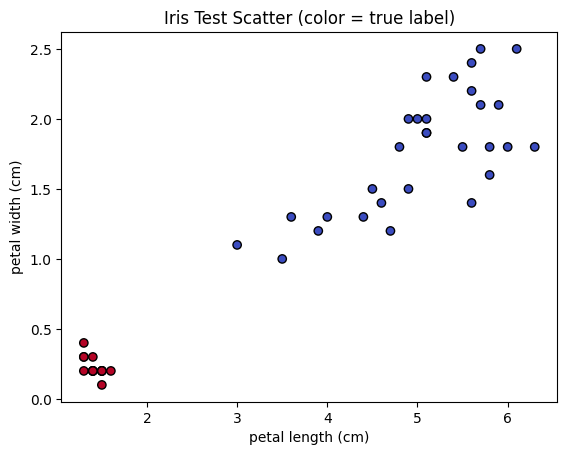

In [ ]:
import matplotlib.pyplot as plt   # 데이터 시각화를 위한 matplotlib 라이브러리

# 산점도(scatter plot) 그리기
# X_test[:,0] → 꽃잎 길이 (petal length)
# X_test[:,1] → 꽃잎 너비 (petal width)
# c=y_test → 실제 라벨(정답: 0/1)에 따라 색상 지정
# cmap='coolwarm' → 파랑/빨강 계열 색상 팔레트
# edgecolors='k' → 점 테두리를 검은색으로 표시
plt.scatter(X_test[:,0], X_test[:,1], c=y_test, cmap='coolwarm', edgecolors='k')

# x축, y축 이름 지정
plt.xlabel('petal length (cm)')
plt.ylabel('petal width (cm)')

# 그래프 제목
plt.title('Iris Test Scatter (color = true label)')

# 그래프 출력
plt.show()